# 05. Duplicate Detection Preprocessing & Entity Preservation

Investigation of text normalization for duplicate detection, demonstrating how aggressive number and date removal creates false duplicate merges, and testing preprocessing on the 300-pair split-isolated benchmark.

**Dataset Release:** `achievement_dataset_v1.0.1` | **Author:** Member 1 (NLP & Semantic Intelligence Engineer)

## 1. Imports & Setup

In [1]:
import sys
from pathlib import Path
repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import csv
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from nlp.text_preprocessing import (
    prepare_text_for_duplicate_detection,
    compare_preprocessing_outputs
)

print("Duplicate detection analysis dependencies imported.")

Duplicate detection analysis dependencies imported.


## 2. Load Duplicate Pair Benchmark Dataset
We load `data/annotations/achievement_duplicate_pairs.csv` (300 pairs: 150 positive, 150 hard negative).

In [2]:
pairs_df = pd.read_csv(REPO_ROOT / "data" / "annotations" / "achievement_duplicate_pairs.csv")
print(f"Total benchmark pairs: {len(pairs_df)}")
print(f"Positive pairs (Label 1): {(pairs_df['duplicate_label'] == 1).sum()}")
print(f"Negative pairs (Label 0): {(pairs_df['duplicate_label'] == 0).sum()}")

print("\nPairs by designated split partition (Zero cross-split leakage):")
print(pairs_df["split"].value_counts().to_string())

Total benchmark pairs: 300
Positive pairs (Label 1): 150
Negative pairs (Label 0): 150

Pairs by designated split partition (Zero cross-split leakage):
split
train         210
validation     46
test           44


## 3. The False Positive Hazard: Why Numerical Indicators Must Be Preserved
We illustrate how aggressive normalization (e.g. replacing or removing numbers and years) collapses distinct achievements into identical strings.

In [3]:
text1 = "Won 1st place in the 2023 National Robotics Olympiad."
text2 = "Won 2nd place in the 2024 National Robotics Olympiad."

# Number-preserving normalization
p1_safe = prepare_text_for_duplicate_detection(text1, preserve_numbers=True)
p2_safe = prepare_text_for_duplicate_detection(text2, preserve_numbers=True)

# Aggressive number-stripping normalization
p1_strip = prepare_text_for_duplicate_detection(text1, preserve_numbers=False)
p2_strip = prepare_text_for_duplicate_detection(text2, preserve_numbers=False)

print("Text A:", repr(text1))
print("Text B:", repr(text2))
print("\nUnder Number-Preserving Normalization:")
print("Text A:", repr(p1_safe))
print("Text B:", repr(p2_safe))
print(f"Are they classified as exact duplicates? {p1_safe == p2_safe} (CORRECT: DISTINCT ACHIEVEMENTS)")

print("\nUnder Aggressive Number-Stripping Normalization:")
print("Text A:", repr(p1_strip))
print("Text B:", repr(p2_strip))
print(f"Are they classified as exact duplicates? {p1_strip == p2_strip} (DANGEROUS FALSE POSITIVE MERGE!)")

Text A: 'Won 1st place in the 2023 National Robotics Olympiad.'
Text B: 'Won 2nd place in the 2024 National Robotics Olympiad.'

Under Number-Preserving Normalization:
Text A: 'won 1st place in the 2023 national robotics olympiad.'
Text B: 'won 2nd place in the 2024 national robotics olympiad.'
Are they classified as exact duplicates? False (CORRECT: DISTINCT ACHIEVEMENTS)

Under Aggressive Number-Stripping Normalization:
Text A: 'won 1st place in the #NUM national robotics olympiad.'
Text B: 'won 2nd place in the #NUM national robotics olympiad.'
Are they classified as exact duplicates? False (DANGEROUS FALSE POSITIVE MERGE!)


## 4. Benchmark Pair Breakdown Visualization
We plot the distribution of duplicate types across positive and hard-negative families.

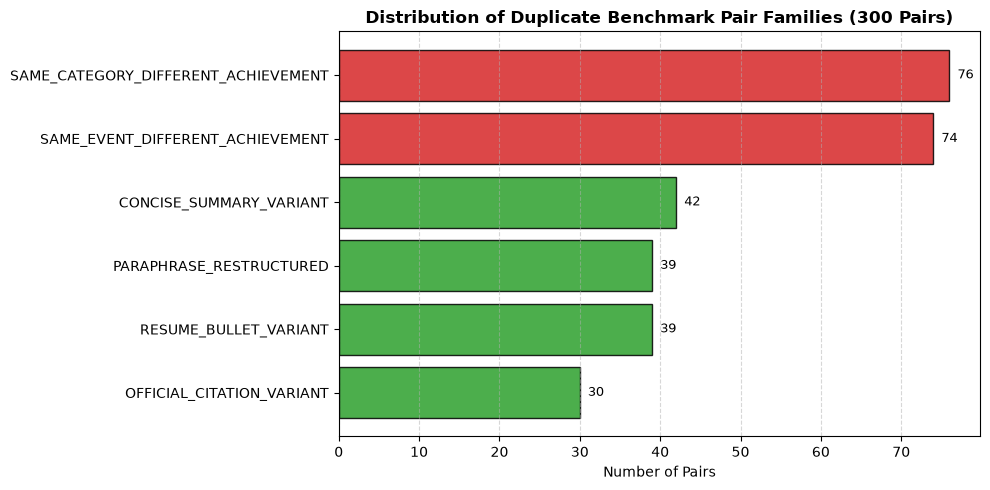

In [4]:
type_counts = pairs_df["duplicate_type"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#2ca02c" if "VARIANT" in t or "PARAPHRASE" in t else "#d62728" for t in type_counts.index]
bars = ax.barh(type_counts.index[::-1], type_counts.values[::-1], color=colors[::-1], edgecolor="black", alpha=0.85)

ax.set_title("Distribution of Duplicate Benchmark Pair Families (300 Pairs)", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Pairs")
ax.grid(True, linestyle="--", alpha=0.5, axis="x")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, f"{int(width)}", ha="left", va="center", fontsize=9)

plt.tight_layout()

## 5. Preprocessing Strategy Recommendations for Member 2
1. **Always Preserve Ordinals & Years:** Retain `1st`, `2nd`, `3rd`, and calendar years `2021`–`2026`.
2. **NFKC Normalization:** Converts compatibility numerals into standard digits.
3. **Lowercasing:** Case folding is safe for duplicate matching provided tokens are preserved.